[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Slice Crawl

There are 8 pizza shops near campus and you want to find the best one.
The catch: you learn about a shop only by tasting its slices.

**Your goal: taste as few slices as possible while still naming the best
shop with at least 95% confidence** (right in at least 95% of crawls).

Each slice gets a rating, but slices vary: the same shop can be great on
Tuesday and soggy on Friday. Each shop's ratings follow a bell curve around
that shop's typical rating, and some shops are more consistent than others.
You don't know any shop's typical rating or consistency.

`SliceCrawl` (in `slice_crawl.py`) runs one crawl. `crawl.taste(i)` buys a
slice from shop `i` and returns its rating. Write `estimate(crawl)`: taste
any shops you like, as many times as you like, then return the shop you
think is best.

- First, clear the bar: name the true best shop in at least 95% of crawls.
- Then, save pizza: among estimators that clear the bar, fewer slices
  (averaged over many crawls) is better.
- Practice on the
  [Slice Crawl site](https://matthigger.github.io/ml_puzzle/slice_crawl/#practice):
  it runs your `estimate()` on as many random crawls as you like and shows
  how it did.
- For fun, we'll race everyone's estimator head to head: fewest slices
  among those that clear 95% wins bragging rights (no effect on your grade).
  Post yours on the site's Leaderboard tab with class code `slice-n30b-xqvq-92e4`.

`evaluate(estimate)` runs your estimator on 200 random crawls and reports
how often it was right and how many slices it tasted on average (the same
`seed` always gives the same crawls). Anything on a crawl that starts with
an underscore (e.g. `crawl._mean`) is the hidden truth: peeking is
cheating. An example estimator:

In [1]:
from slice_crawl import SliceCrawl, evaluate

crawl = SliceCrawl.sample(seed=0)  # one random crawl of 8 shops
print(crawl.taste(3), crawl.taste(3), crawl.n_taste)


def taste_each_5(crawl):
    """ 5 slices from every shop, best average wins """
    avg = [sum(crawl.taste(i) for _ in range(5)) / 5
           for i in range(crawl.n_shop)]
    return avg.index(max(avg))


evaluate(taste_each_5);

5.5158722675697405 4.67064038868554 2
200 crawls: right 76.0% of the time (need 95%), 40.0 slices on average


# Executive summary

*TODO — write 3-4 plain sentences in your own words, then delete these notes. Notes: 96.7% right, 76 slices avg, 10,000 fresh crawls; bar 95%; equal tasting needs ~350 slices for same accuracy; stops tasting shops once clearly worse.*

# Approach

*TODO — a few bullets in your own words, then delete these notes. Notes: 2 slices per shop first; drop shop if leader beats it by > c·√(1+40/n) std errors (c = 0.8, n = fewer slices of the two); each round taste leader + 2 closest rivals; spread estimate combines shop's slices with known range 0.5–2.5; cap 3000. Assumptions: bell-shaped independent ratings, spreads in 0.5–2.5 (generator). Settings chosen on seeds 100–107, results on fresh seed 1; ± = 2 standard errors.*

10000 fresh crawls: right 96.7% (± 0.4%), 76 slices on average


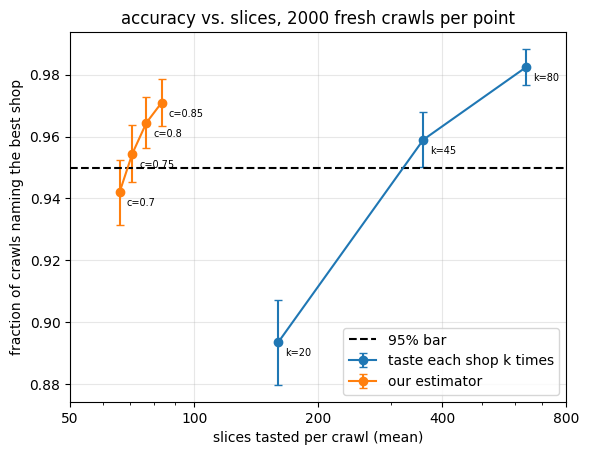

In [2]:
import matplotlib.pyplot as plt
from slice_helpers import estimate, make_estimator, taste_each, run, plot_tradeoff, plot_accuracy_by_gap

best = run(estimate, n_crawl=10000, seed=1)  # fresh crawls: settings were tuned on other seeds
print(f"10000 fresh crawls: right {best['accuracy']:.1%} (± {2 * best['accuracy_se']:.1%}), "
      f"{best['mean_slices']:.0f} slices on average")
k_all, c_all = [20, 45, 80], [.7, .75, .8, .85]
curves = {'taste each shop k times': ([f'k={k}' for k in k_all], [run(taste_each(k)) for k in k_all]),
          'our estimator': ([f'c={c}' for c in c_all], [run(make_estimator(c)) for c in c_all])}
fig, ax = plt.subplots()
plot_tradeoff(ax, curves)
ax.set_title('accuracy vs. slices, 2000 fresh crawls per point');

*TODO — one sentence in your own words: what to notice. Notes: our curve far left of equal tasting; c = 0.8 clears 95% at ~75 slices vs ~350.*

stress test 'heavy': right 96.8%, 69 slices


stress test 'disaster': right 93.9%, 93 slices


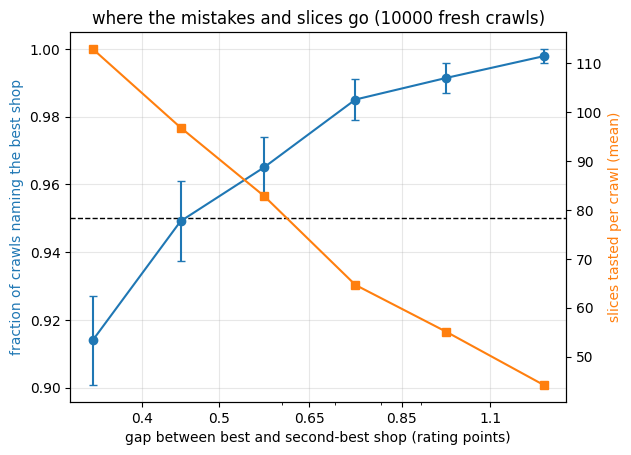

In [3]:
fig, ax = plt.subplots()
plot_accuracy_by_gap(ax, best)
ax.set_title('where the mistakes and slices go (10000 fresh crawls)')
for family in ['heavy', 'disaster']:
    r = run(estimate, family=family)
    print(f"stress test '{family}': right {r['accuracy']:.1%}, {r['mean_slices']:.0f} slices")

*TODO — one sentence in your own words. Notes: gap ~0.3 → ~91% right, ~113 slices; gap > 1 → >99%, ~44 slices; heavy 96.8% ok; disaster 93.9% below bar (assumes bell-shaped ratings).*